In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Introduction

Customer churn occurs when customers stop using a company's products or services. In the telecommunications industry, understanding why customers leave is important because it helps businesses improve customer satisfaction, strengthen loyalty and reduce revenue losses.

### Understanding the Dataset

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

### Load the Dataset

In [2]:
# Load dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
#Check the dataset structure
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
df.describe(include='O')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


## Exploratory Data Analysis (EDA)

Before building the models, I will examine the dataset to understand customer behaviour and identify patterns associated with churn.

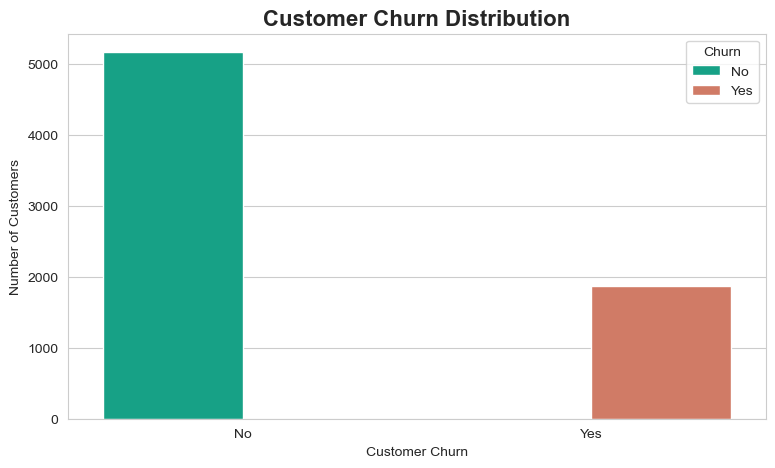

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette=['#00B894', '#E17055'],
    )

plt.title("Customer Churn Distribution",
          fontsize=16, fontweight='bold')

plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

The dataset contains more customers who stayed than customers who left. This indicates class imbalance, which is important when evaluating the machine learning models.

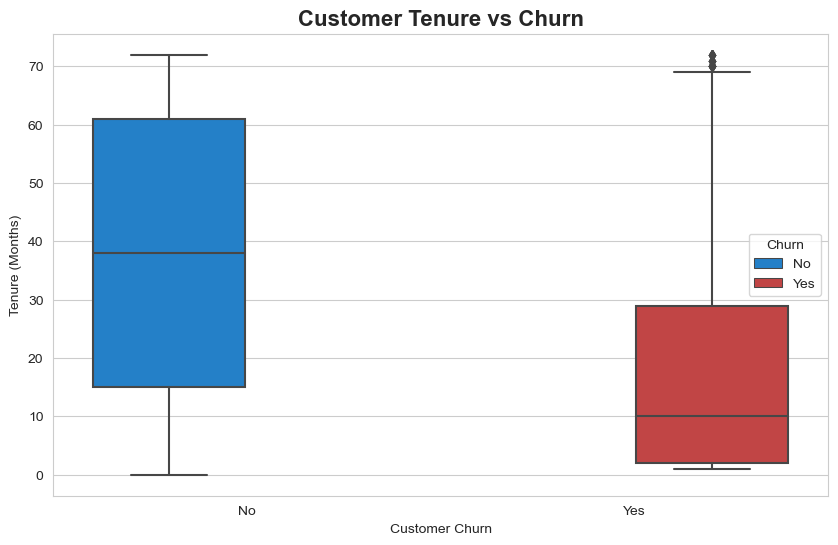

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure',
    hue='Churn',
    palette=['#0984E3', '#D63031'],
    )

plt.title("Customer Tenure vs Churn",
          fontsize=16, fontweight='bold')

plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.show()

Customer tenure is important because customers who have stayed for shorter periods may be more vulnerable to leaving.

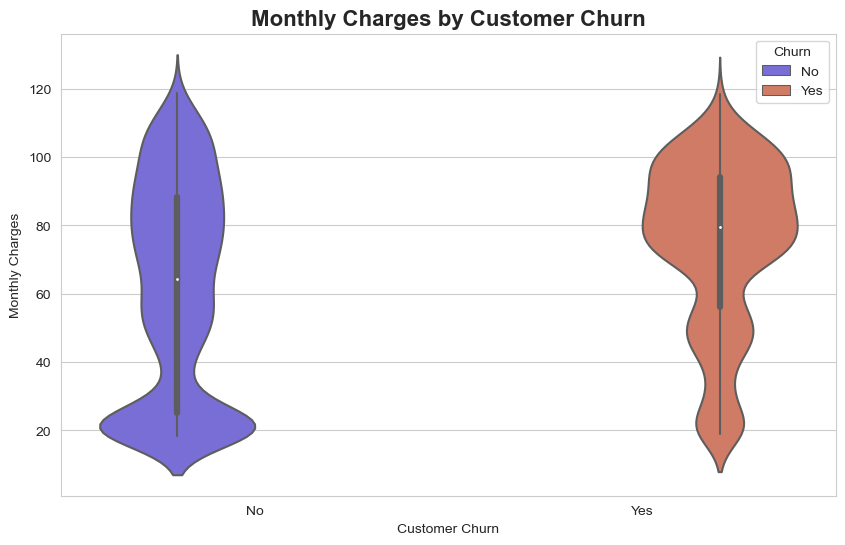

In [14]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette=['#6C5CE7', '#E17055'],
    )

plt.title("Monthly Charges by Customer Churn",
          fontsize=16, fontweight='bold')

plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()

This visualization helps investigate whether customers paying higher monthly charges demonstrate different churn patterns.

### Correlation Heatmap

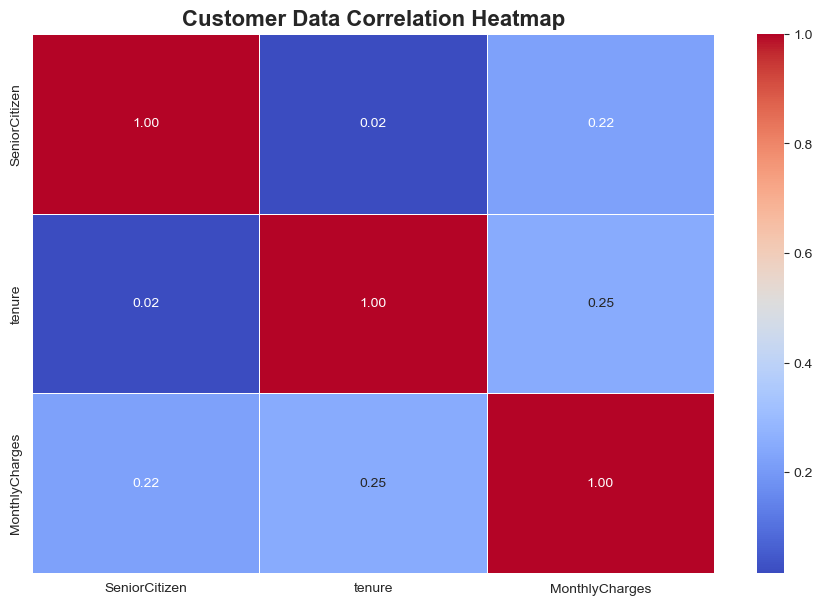

In [15]:
plt.figure(figsize=(11, 7))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt='.2f'
)

plt.title("Customer Data Correlation Heatmap",
          fontsize=16, fontweight='bold')

plt.show()

### Data Preprocessing

In [16]:
# Create a copy
data = df.copy()

# Convert TotalCharges to numeric
data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'],
    errors='coerce'
)

# Convert target variable
data['Churn'] = data['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Remove customerID
data.drop(columns=['customerID'], inplace=True)

print(data.head())

print("\nMissing Values:")
print(data.isnull().sum())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [17]:
# Independent variables
X = data.drop('Churn', axis=1)

# Dependent variable
y = data['Churn']

# Identify numerical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numeric_features)

print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Create Preprocessing Pipeline

In [18]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

### Train/Test Splitting

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)


## Logistic Regression

In [20]:
# Create Logistic Regression model
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test)

# Prediction probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")

print(classification_report(
    y_test,
    logistic_predictions
))

Logistic Regression Results
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## Logistic Regression Evaluation

In [21]:
print("Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("Precision:",
      precision_score(y_test, logistic_predictions))

print("Recall:",
      recall_score(y_test, logistic_predictions))

print("F1 Score:",
      f1_score(y_test, logistic_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, logistic_probabilities))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262
ROC-AUC: 0.8414606422279056


## Random Forest Classifier

In [22]:
# Create Random Forest model
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced',
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

# Make predictions
rf_predictions = random_forest_model.predict(X_test)

# Prediction probabilities
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")

print(classification_report(
    y_test,
    rf_predictions
))

Random Forest Results
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1035
           1       0.58      0.65      0.61       374

    accuracy                           0.78      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



## Random Forest Evaluation

In [23]:
print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions))

print("Recall:",
      recall_score(y_test, rf_predictions))

print("F1 Score:",
      f1_score(y_test, rf_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_probabilities))

Accuracy: 0.7842441447835344
Precision: 0.5845410628019324
Recall: 0.6470588235294118
F1 Score: 0.6142131979695432
ROC-AUC: 0.8346831486217675


## Support Vector Machine (SVM)

In [24]:
# Create SVM model
svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        class_weight='balanced',
        random_state=42
    ))
])

# Train model
svm_model.fit(X_train, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test)

# Prediction probabilities
svm_probabilities = svm_model.predict_proba(X_test)[:, 1]

print("SVM Results")

print(classification_report(
    y_test,
    svm_predictions
))

SVM Results
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.77      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



## SVM Evaluation

In [25]:
print("Accuracy:",
      accuracy_score(y_test, svm_predictions))

print("Precision:",
      precision_score(y_test, svm_predictions))

print("Recall:",
      recall_score(y_test, svm_predictions))

print("F1 Score:",
      f1_score(y_test, svm_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, svm_probabilities))

Accuracy: 0.7437899219304471
Precision: 0.511504424778761
Recall: 0.7727272727272727
F1 Score: 0.6155484558040468
ROC-AUC: 0.8210648686352011


## Compare the Three Models

In [26]:
# Store model results
results = {
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest_model,
    'SVM': svm_model
}

# Create evaluation table
comparison = []

for name, model in results.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.7381     0.5043  0.7834    0.6136   0.8415
1        Random Forest    0.7842     0.5845  0.6471    0.6142   0.8347
2                  SVM    0.7438     0.5115  0.7727    0.6155   0.8211


## Visualize Model Performance

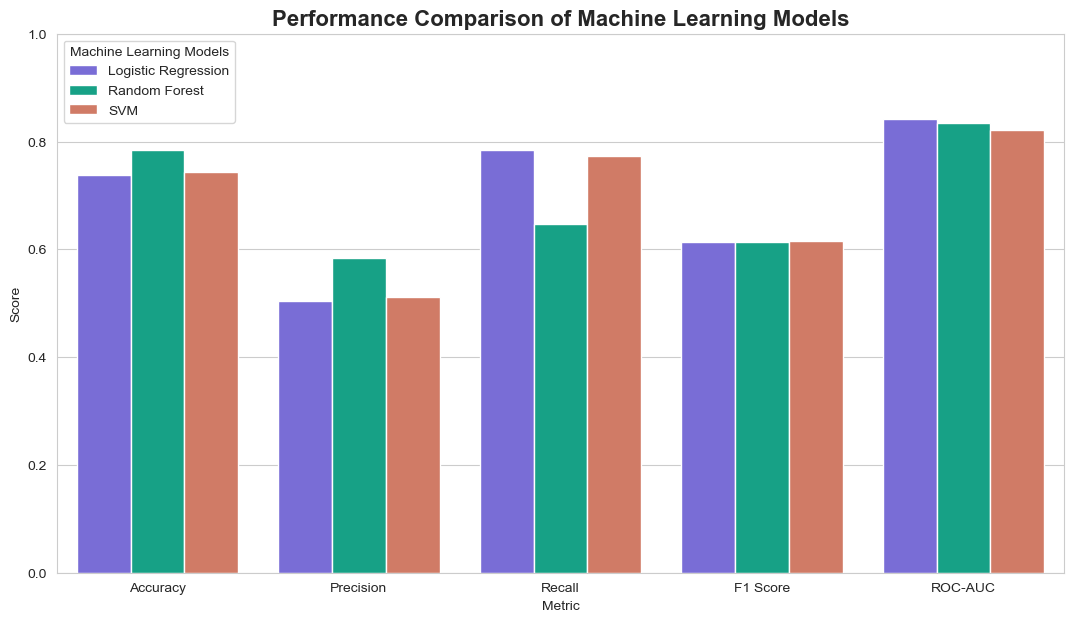

In [27]:
comparison_melted = comparison_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=comparison_melted,
    x='Metric',
    y='Score',
    hue='Model',
    palette=['#6C5CE7', '#00B894', '#E17055']
)

plt.title(
    "Performance Comparison of Machine Learning Models",
    fontsize=16,
    fontweight='bold'
)

plt.ylim(0, 1)
plt.legend(title='Machine Learning Models')
plt.show()

## Confusion Matrix Visualization

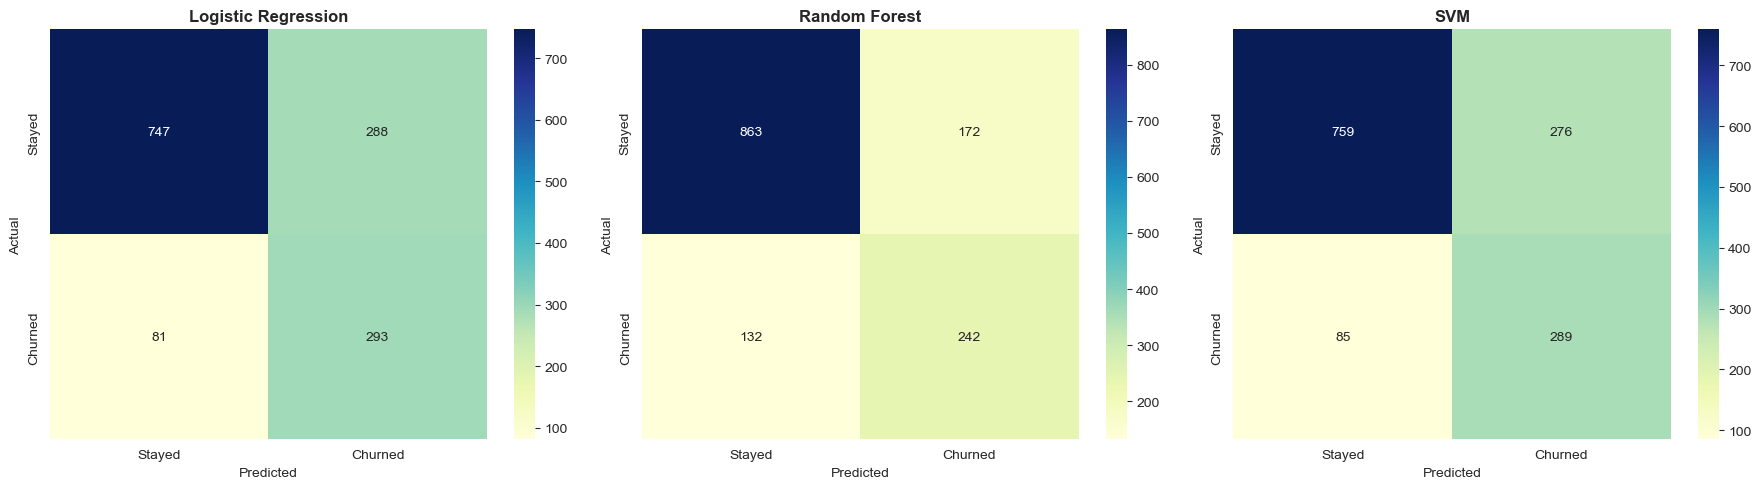

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_predictions = [
    ('Logistic Regression', logistic_predictions),
    ('Random Forest', rf_predictions),
    ('SVM', svm_predictions)
]

for ax, (name, predictions) in zip(
    axes, model_predictions
):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        xticklabels=['Stayed', 'Churned'],
        yticklabels=['Stayed', 'Churned'],
        ax=ax
    )

    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## ROC Curve Comparison

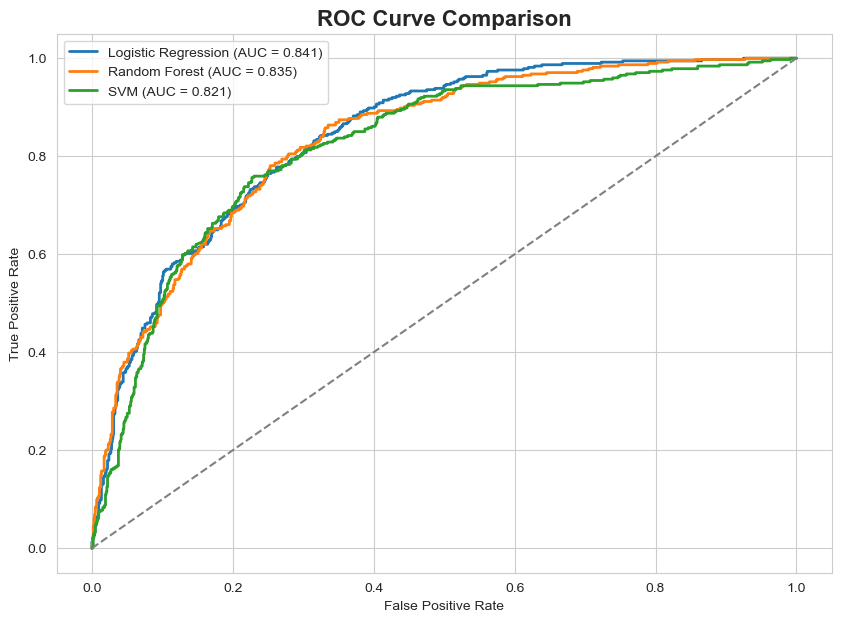

In [31]:
plt.figure(figsize=(10, 7))

model_probabilities = {
    'Logistic Regression': logistic_probabilities,
    'Random Forest': rf_probabilities,
    'SVM': svm_probabilities
}

for name, probabilities in model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray'
)

plt.title(
    "ROC Curve Comparison",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

## Prediction Example

Finally, we will use the trained models to predict whether a new customer is likely to leave the company.
The example below uses an existing customer record from the testing dataset.

In [32]:
# Select one customer from the test dataset
new_customer = X_test.iloc[[0]]

# Predict using all three models
logistic_result = logistic_model.predict(new_customer)[0]

rf_result = random_forest_model.predict(new_customer)[0]

svm_result = svm_model.predict(new_customer)[0]

# Convert numerical predictions into readable results
def churn_status(value):

    return "Likely to Churn" if value == 1 else "Likely to Stay"


print("CUSTOMER CHURN PREDICTION")

print("----------------------------")

print("Logistic Regression:",
      churn_status(logistic_result))

print("Random Forest:",
      churn_status(rf_result))

print("SVM:",
      churn_status(svm_result))

CUSTOMER CHURN PREDICTION
----------------------------
Logistic Regression: Likely to Stay
Random Forest: Likely to Stay
SVM: Likely to Stay


In [33]:
print("LOGISTIC REGRESSION:",
      round(logistic_model.predict_proba(new_customer)[0][1] * 100, 2),
      "% churn probability")

print("RANDOM FOREST:",
      round(random_forest_model.predict_proba(new_customer)[0][1] * 100, 2),
      "% churn probability")

print("SVM:",
      round(svm_model.predict_proba(new_customer)[0][1] * 100, 2),
      "% churn probability")

LOGISTIC REGRESSION: 11.64 % churn probability
RANDOM FOREST: 0.62 % churn probability
SVM: 5.32 % churn probability


## Final Project Conclusion

Through this machine learning project, I developed three classification models to predict customer churn using telecommunications customer information.Overall, I found that customer churn prediction can help telecommunications companies identify customers who may discontinue their services. By using these predictions, businesses can introduce targeted retention strategies, improve customer experiences and make better decisions to reduce customer losses.

My recommendation: Use Logistic Regression when the primary objective is to identify as many potential churners as possible. Consider Random Forest when reducing false alarms is more important.